Here's your Post 3 prompt:    
Topic: Class imbalance: when 73% accuracy means nothing.   
Area: Machine Learning.   
Type: build.   
Constraints:  
- Max 800 words (about a 4-minute read)
- End with one question for the reader
- NumPy and the standard library only (no scikit-learn)
- Add 3 test cases, including one edge case
Saved the prompt as used.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load the raw data

In [2]:
df = pd.read_csv('employee_attrition_raw.csv')
print(df.shape)
df.head()

(460, 16)


,EmployeeID,Age,Gender,Department,JobRole,Education,MaritalStatus,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,DistanceFromHome,OverTime,JobSatisfaction,WorkLifeBalance,PerformanceRating,Attrition
0,EMP1044,36.0,Male,Research & Development,Manager,Bachelor's,single,5337,0.0,0.0,8.0,No,3.0,4.0,3.0,No
1,EMP1191,40.0,Female,R&D,Manufacturing Director,High School,Divorced,8263,5.0,0.0,8.0,No,3.0,2.0,3.0,no
2,EMP1282,29.0,Female,Research & Development,Laboratory Technician,Associate's,single,7340,5.0,0.0,8.0,No,3.0,4.0,3.0,No
3,EMP1429,21.0,Male,Sales,Sales Executive,High School,Married,5576,2.0,0.0,2.0,No,3.0,1.0,4.0,Yes
4,EMP1336,45.0,Male,Human Resources,Manager,Associate's,Divorced,6069,0.0,0.0,3.0,Yes,2.0,3.0,4.0,Yes


## 2. Remove impossible values
Negative ages, negative tenure and negative distances are data-entry errors.

In [3]:
df = df[df['Age'] > 0]
df = df[df['YearsAtCompany'] >= 0]
df = df[df['DistanceFromHome'] > 0]
df.shape

(428, 16)

## 3. Fix text columns
Strip spaces, use one case, and merge spellings of the same thing.

In [4]:
for col in ['Department', 'MaritalStatus', 'Gender', 'OverTime', 'Education']:
    df[col] = df[col].str.strip().str.lower()

df['Department'] = df['Department'].replace({'research & development': 'r&d', 'hr': 'human resources'})

# Attrition had No/no/N/Yes/yes/Y -> keep the first letter: 'n' or 'y'
df['Attrition'] = df['Attrition'].str.strip().str.lower().str[0]

for col in ['Department', 'MaritalStatus', 'Attrition', 'OverTime']:
    print(col, df[col].unique())

Department <StringArray>
['r&d', 'sales', 'human resources', nan]
Length: 4, dtype: str
MaritalStatus <StringArray>
['single', 'divorced', 'married']
Length: 3, dtype: str
Attrition <StringArray>
['n', 'y']
Length: 2, dtype: str
OverTime <StringArray>
['no', 'yes']
Length: 2, dtype: str


## 4. Fix numbers stored as text
MonthlyIncome had thousands separators like '6,589'.

In [5]:
df['MonthlyIncome'] = df['MonthlyIncome'].str.replace(',', '').astype(float)

## 5. Fill missing values
Numbers: median (robust to outliers). Categories: most common value (mode).

In [6]:
for col in ['MonthlyIncome', 'JobSatisfaction', 'WorkLifeBalance', 'PerformanceRating', 'YearsAtCompany']:
    df[col] = df[col].fillna(df[col].median())

for col in ['Department', 'Education', 'Gender', 'MaritalStatus', 'OverTime']:
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum()

EmployeeID            0
Age                   0
Gender                0
Department            0
JobRole               0
Education             0
MaritalStatus         0
MonthlyIncome         0
YearsAtCompany        0
YearsInCurrentRole    0
DistanceFromHome      0
OverTime              0
JobSatisfaction       0
WorkLifeBalance       0
PerformanceRating     0
Attrition             0
dtype: int64

## 6. Make the classes 73:27
The cleaned data is about 68:32 (no:yes). To mirror the 73% accuracy trap from my churn project, I resample extra 'no' rows (random duplicates of existing 'no' rows).

In [7]:
print(df['Attrition'].value_counts())

n_yes = (df['Attrition'] == 'y').sum()
target_no = round(n_yes * 73 / 27)
no_rows = df[df['Attrition'] == 'n']
rows_to_add = target_no - len(no_rows)

np.random.seed(42)
positions = np.random.choice(len(no_rows), size=rows_to_add, replace=True)
extra = no_rows.iloc[positions]
df = pd.concat([df, extra], ignore_index=True)

print(df.shape)
df['Attrition'].value_counts(normalize=True)

Attrition
n    292
y    136
Name: count, dtype: int64
(504, 16)


Attrition
n    0.730159
y    0.269841
Name: proportion, dtype: float64

## 7. Numeric versions for analysis

In [8]:
df['Attrition_num'] = df['Attrition'].map({'y': 1, 'n': 0})
df['OverTime_num'] = df['OverTime'].map({'yes': 1, 'no': 0})
df[['Attrition_num', 'OverTime_num']].isnull().sum()

Attrition_num    0
OverTime_num     0
dtype: int64

## 8. Which features relate to attrition?

In [9]:
df.corr(numeric_only=True)['Attrition_num'].sort_values(ascending=False)

Attrition_num         1.000000
OverTime_num          0.184588
PerformanceRating     0.069431
YearsInCurrentRole    0.013530
Age                  -0.023984
MonthlyIncome        -0.036204
DistanceFromHome     -0.075319
JobSatisfaction      -0.114428
WorkLifeBalance      -0.118821
YearsAtCompany       -0.121771
Name: Attrition_num, dtype: float64

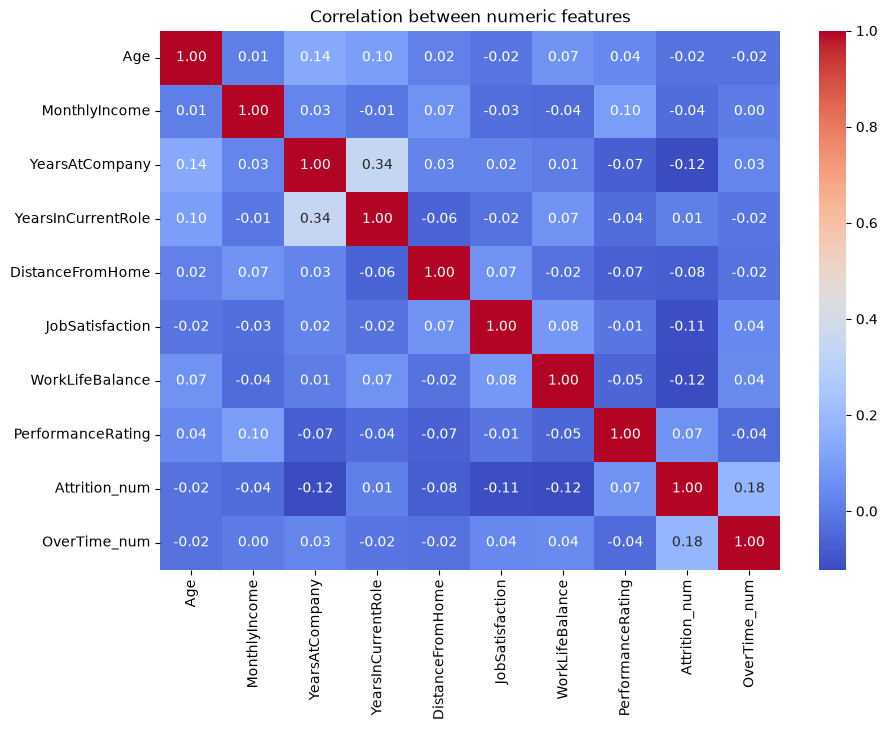

In [10]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric features')
plt.show()

## 9. Metrics (my code from here, unchanged)

In [11]:
# Making predictions using numpy
y_true = df['Attrition'].map({'y':1, 'n':0}).to_numpy()

In [12]:
df['Attrition'].unique()

<StringArray>
['n', 'y']
Length: 2, dtype: str

In [13]:
# Actual counts
negative = df[df['Attrition_num']==0].value_counts().sum()
positive = df[df['Attrition_num']==1].value_counts().sum()

In [14]:
df.describe()

,Age,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,DistanceFromHome,JobSatisfaction,WorkLifeBalance,PerformanceRating,Attrition_num,OverTime_num
count,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000
mean,35.049603,6139.863095,4.035714,0.888889,7.265873,2.611111,2.581349,3.085317,0.269841,0.321429
std,10.213210,8884.300395,4.330611,1.359583,6.781798,1.138324,1.132095,0.734456,0.444318,0.467489
min,18.000000,1500.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,29.000000,4286.500000,1.000000,0.000000,2.000000,2.000000,2.000000,3.000000,0.000000,0.000000
50%,35.000000,5460.500000,3.000000,0.000000,5.000000,3.000000,3.000000,3.000000,0.000000,0.000000
75%,41.000000,6519.000000,6.000000,1.000000,11.000000,4.000000,4.000000,4.000000,1.000000,1.000000
max,150.000000,137680.000000,28.000000,8.000000,38.000000,4.000000,4.000000,4.000000,1.000000,1.000000


In [15]:
df['YearsInCurrentRole'].unique()

array([0., 1., 2., 3., 4., 6., 7., 5., 8.])

In [16]:
# making predictions
def make_preds(test):
    y_preds = []
    for val in test:
        if val == 1:
            attrition = 1
        else:
            attrition = 0
        y_preds.append(attrition)
    return np.array(y_preds)

y_preds = make_preds(df['OverTime_num'].to_numpy())
y_preds

array([0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [17]:
# actual counts
actual_positives = np.bincount(y_true)[1]
actual_negatives = np.bincount(y_true)[0]

In [18]:
# predicted counts
predicted_positives = np.bincount(y_preds)[1]
predicted_negatives = np.bincount(y_preds)[0]


In [19]:
# deriving the confusion matrix manually

# True Positives: Actual Positive that was predicted correctly
TP = ((y_true == 1) & (y_preds == 1)).sum()

# True Negatives: Actual Negatives that were predicted correctly
TN = ((y_true == 0) & (y_preds == 0)).sum()

# False Positives: Actual Negatives that were predicted wrongly
FP = ((y_true == 0) & (y_preds == 1)).sum()

# False Negatives: Actual Positives that were predicted wrongly
FN = ((y_true == 1) & (y_preds == 0)).sum()

In [20]:
# accuracy: of all the predictions and actuals, how many were predicted correctly
accuracy = (TP + TN) / (TP + TN + FP + FN)

# precision: of all the predicted positives, how many were predicted correctly
precision = TP / (TP + FP)

# recall: of all the actual positives, how many were predicted correctly
recall = TP / (TP + FN)

# specificity: of all the actual negatives, how many were predicted correctly
specificity = TN / (TN + FP)

# F1: score is the harmonic mean of precision and recall - used to measure a model's accuracy, particularly when dealing with imbalanced datasets.
f1_score = 2 * (precision * recall) / (precision + recall)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"Specificity: {specificity}")
print(f"F1 score: {f1_score}")

Accuracy: 0.6587301587301587
Precision: 0.3888888888888889
Recall: 0.4632352941176471
Specificity: 0.7309782608695652
F1 score: 0.42281879194630867


# Test cases:
1. Normal case: the decent model; True Positive = 1, False Negative = 1, Recall = 0.5, Precision = 0.75
2. Perfect case: the perfect model; True Positive = 1, False Negative = 1, Recall = 1, Precision = 1
3. Edge case: the lazy model; True Positive = 0, False Negative = 0, Recall = 0, Precision = 0

In [21]:
# function get metrics
def get_metrics(y_true, y_preds):
    # True Positives: Actual Positive that was predicted correctly
    TP = ((y_true == 1) & (y_preds == 1)).sum()

    # True Negatives: Actual Negatives that were predicted correctly
    TN = ((y_true == 0) & (y_preds == 0)).sum()

    # False Positives: Actual Negatives that were predicted wrongly
    FP = ((y_true == 0) & (y_preds == 1)).sum()

    # False Negatives: Actual Positives that were predicted wrongly
    FN = ((y_true == 1) & (y_preds == 0)).sum()

    if (TP + FP) == 0:
        precision = 0
    else:
        precision = TP / (TP + FP)

    if (TP + FN) == 0:
        recall = 0
    else: 
        recall = TP / (TP + FN)

    if (TN + FP) == 0:
        specificity = 0
    else:
        specificity = TN / (TN + FP)

    if (precision + recall) == 0:
        f1_score = 0
    else:
        f1_score = 2 * (precision * recall) / (precision + recall)

    accuracy = (TP + TN) / (TP + TN + FP + FN)

    return accuracy, precision, recall, specificity, f1_score

# tests
y_true_test = np.array([1,0,1,0])

# 1. Normal case
acc, prec, rec, spec, f1 = get_metrics(y_true_test, np.array([1, 0, 0, 0]))
assert rec == 0.5
assert prec == 1.0

# 2. Perfect case
acc, prec, rec, spec, f1 = get_metrics(y_true_test, y_true_test)
assert acc == 1.0
assert rec == 1.0

# 3. edge: model predicts no positives
acc, prec, rec, spec, f1 = get_metrics(y_true_test, np.array([0, 0, 0, 0]))
assert prec == 0     
assert rec == 0

print("All 3 tests passed")  

All 3 tests passed
